# Kelvin-Helmholtz: linear growth and McNally et al. (2012)

1. **Linear growth.** A smooth shear layer (velocity jump 1, sound speed 2, gamma = 5/3) seeded
   with its exact compressible eigenmode at amplitude 1e-6 grows as exp(sigma t). The growth rate
   sigma and the eigenfunction come from the linearised equations
   (`luna.hydro.exact_kh_linear`, the setup of `tests/test_hydro_accuracy_kh.py`). Compared: the
   fitted growth rate against sigma, and the error of v_y at t = 4, at 32 x 64 and 64 x 128.
2. **Nonlinear KH, McNally, Lyra & Passy (2012, ApJS 201, 18).** The registered `KH-McNally-2D`
   problem with the paper's parameters, MC limiter, against the paper's 4096² Pencil Code
   reference for the mode amplitude M(t) (their fig. 4), at 64² and 128² to t = 1.5.

Runtime: about 1.5 minutes on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
import glob
from luna.file_io.read_snapshot import read_snapshot
from luna.hydro.exact_kh_linear import cell_average_y, geometry, linear_mode, profile

g = geometry()
sigma, q, _ = linear_mode(g)[:3]
AMP, T = 1e-6, 4.0
print(f"linear theory: sigma = {sigma.real:.5f} (box {g['Lx']:.4f} x {g['Ly']:.4f})")


def phase_x(nx):
    """Cell averages of exp(i k x)."""
    x = (np.arange(nx) + 0.5) * g["Lx"] / nx
    return np.exp(1j * g["k"] * x) * np.sinc(g["k"] * g["Lx"] / nx / (2 * np.pi))


def seeded(nx):
    """The layer plus AMP times the eigenmode on nx x 2nx cells (isentropic: rho' = p' / cs^2)."""
    ny = 2 * nx
    y = (np.arange(ny) + 0.5) * g["Ly"] / ny
    up, vp, pp = (AMP * np.real(phase_x(nx)[:, None] * cell_average_y(q[i], g["Ly"], ny)[None, :]) for i in range(3))
    u = profile(y, g["Ly"], g["d"], g["dU"])[None, :] + up
    rho, p = g["rho"] + pp / g["cs"] ** 2, g["p"] + pp
    U = np.zeros((4, nx, ny))                     # rho, rho vx, rho vy, E
    U[0], U[1], U[2] = rho, rho * u, rho * vp
    U[3] = p / (g["gamma"] - 1) + 0.5 * rho * (u * u + vp * vp)
    return U

linear theory: sigma = 1.25739 (box 1.0000 x 2.0000)


In [3]:
# measured by the test (CPU, FP64, HLLC-minmod) at 32, 64: |sigma_fit/sigma - 1| = 0.164, 0.03;
# L1 of (v_y - exact) / (AMP e^{sigma T}) = 0.174, 0.0433
lin = {}
for nx in (32, 64):
    cfg = replace(BASE, test_problem="KH-Eigenmode", SPATIAL_DIMENSION=2, Nx=nx, Ny=2 * nx,
                  Lx=g["Lx"], Ly=g["Ly"], BOUNDARY=0, gamma=g["gamma"], t_end=T,
                  time_bet_snaps=0.25, output_dir=f"snapshots/nb08/lin{nx}")
    res, wall = run(cfg, U0=seeded(nx))
    snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))]
    t = np.array([s["t"] for s in snaps])
    a = np.array([np.sqrt(np.sum(np.abs(np.fft.rfft(s["vy"], axis=0)[1]) ** 2)) for s in snaps])
    s_fit = np.polyfit(t, np.log(a), 1)[0]
    exact = np.real(phase_x(nx)[:, None] * cell_average_y(q[1], g["Ly"], 2 * nx)[None, :] * np.exp(sigma * T))
    e = (snaps[-1]["vy"] - AMP * exact) / (AMP * np.exp(sigma.real * T))
    lin[nx] = (t, a)
    print(f"{nx}x{2 * nx}: sigma_fit = {s_fit:.5f}, |sigma_fit/sigma - 1| = {abs(s_fit / sigma.real - 1):.4f}, "
          f"L1 v_y error at t = 4: {np.abs(e).mean():.4f}   ({wall:.1f} s)")

32x64: sigma_fit = 1.05071, |sigma_fit/sigma - 1| = 0.1644, L1 v_y error at t = 4: 0.1737   (3.8 s)


64x128: sigma_fit = 1.21964, |sigma_fit/sigma - 1| = 0.0300, L1 v_y error at t = 4: 0.0433   (6.5 s)


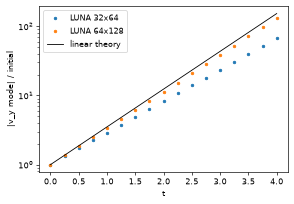

In [4]:
fig, a = plt.subplots(figsize=(5, 3.5), dpi=60)
tt = np.linspace(0, T, 50)
for nx, (t, amp) in lin.items():
    a.semilogy(t, amp / amp[0], "o", ms=3, label=f"LUNA {nx}x{2 * nx}")
a.semilogy(tt, np.exp(sigma.real * tt), "k-", lw=1, label="linear theory")
a.set_xlabel("t"); a.set_ylabel("|v_y mode| / initial"); a.legend()
fig.tight_layout()

## McNally et al. (2012)

The reference curves live in the separate repository
[luna-reference-solutions](https://github.com/Ulli1991/luna-reference-solutions), read through
`luna.reference_data` (sha256-checked; a missing file is an error). Get it with

```bash
git clone https://github.com/Ulli1991/luna-reference-solutions
export LUNA_REFERENCE_SOLUTIONS=$PWD/luna-reference-solutions
```

(or clone it next to the LUNA checkout, or into your home directory, where it is found without
the variable). M is the amplitude of the sin(4 pi x) mode of v_y weighted towards the two
interfaces (McNally eqs. 6-9).

In [5]:
from luna.ic_generation import kh_mcnally
from luna.reference_data import reference_path

t_ref, M_ref, _ = np.loadtxt(reference_path("pencil/mcnally_kh/mcnally2012_fig4_Mref.txt"), unpack=True)


def mode_amplitude(rho, vy):
    """M of McNally eqs. 6-9 on an n x n grid of the unit box."""
    n = vy.shape[0]
    c = (np.arange(n) + 0.5) / n
    w = np.where(c < 0.5, np.exp(-4 * np.pi * np.abs(c - 0.25)), np.exp(-4 * np.pi * np.abs((1.0 - c) - 0.25)))
    s, co = np.sin(4 * np.pi * c) @ vy @ w, np.cos(4 * np.pi * c) @ vy @ w
    return float(2.0 * np.hypot(s, co) / (n * w.sum()))


# measured by the test (CPU, FP64, MC): max over t <= 1.5 of |M/M_ref - 1| = 0.240 (64²), 0.0389 (128²)
mc = {}
for n in (64, 128):
    cfg = replace(BASE, test_problem="KH-McNally-2D", SPATIAL_DIMENSION=2, Nx=n, Ny=n,
                  Lx=1.0, Ly=1.0, BOUNDARY=0, gamma=5.0 / 3.0, LIMITER=1, problem=kh_mcnally.Params(),
                  t_end=1.5, time_bet_snaps=0.02, output_dir=f"snapshots/nb08/mcnally{n}")
    res, wall = run(cfg)
    snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))]
    t = np.array([s["t"] for s in snaps])
    assert np.abs(t - t_ref).max() < 1e-9, "snapshot times are not the reference's"
    M = np.array([mode_amplitude(s["rho"], s["vy"]) for s in snaps])
    mc[n] = (t, M, res.extra["U"])
    print(f"{n}²: {res.n_steps} steps, max_t |M/M_ref - 1| = {np.abs(M / M_ref - 1).max():.4f}   ({wall:.1f} s)")

64²: 600 steps, max_t |M/M_ref - 1| = 0.2403   (6.2 s)


128²: 1133 steps, max_t |M/M_ref - 1| = 0.0389   (7.5 s)


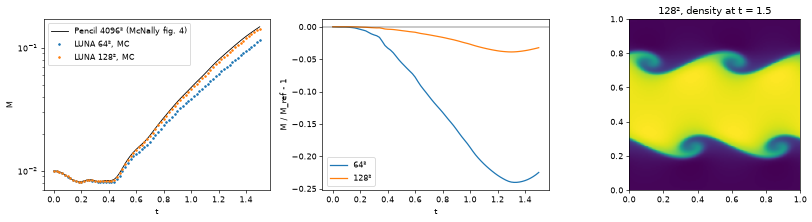

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), dpi=60)
ax[0].semilogy(t_ref, M_ref, "k-", lw=1, label="Pencil 4096² (McNally fig. 4)")
for n, (t, M, _) in mc.items():
    ax[0].semilogy(t, M, "o", ms=2, label=f"LUNA {n}², MC")
    ax[1].plot(t, M / M_ref - 1, "-", label=f"{n}²")
ax[0].set_xlabel("t"); ax[0].set_ylabel("M"); ax[0].legend()
ax[1].axhline(0, color="k", lw=0.5); ax[1].set_xlabel("t"); ax[1].set_ylabel("M / M_ref - 1"); ax[1].legend()
ax[2].imshow(np.asarray(mc[128][2])[0].T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
ax[2].set_title("128², density at t = 1.5")
fig.tight_layout()

**What this shows.** Linear: the fitted growth rate is 16 % low at 32 x 64 and 3 % low at 64 x 128, and the v_y error falls by 4 per doubling; both are the test's values. McNally: max over t of |M/M_ref - 1| is 0.24 at 64² and 0.039 at 128², the test's values; the error falls by about 6 per doubling.

Status (docs/CLAIMS.md): linear growth of KH against linear theory *validated*,
`tests/test_hydro_accuracy_kh.py:87`; nonlinear KH against the Pencil Code reference *validated*,
`tests/test_hydro_hard_mcnally_kh.py:277`. The 8192² comparison with AthenaK in the README is
*shown* (by eye), not asserted.